# SelfCheckGPT on the Newly Constructed Dataset

In [ ]:
# Restart after running this cell.
!pip install -q selfcheckgpt bitsandbytes accelerate
!python -m spacy download en_core_web_sm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, gc, re, json, time, pickle, hashlib, functools, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import spacy
from tqdm.auto import tqdm
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = "/content/drive/MyDrive/NewDatasetConstruction"
except ImportError:
    BASE_DIR = "./selfcheckgpt_results"
DATA_DIR = os.path.join(BASE_DIR, "new_domain")
os.makedirs(DATA_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}" + (f" - {torch.cuda.get_device_name(0)}" if device.type == "cuda" else "  (WARNING: NLI / BERTScore / Prompt need a GPU)"))
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if device.type == "cuda" else 0.0

# selfcheckgpt re-loads the spaCy model on every call;
if not hasattr(spacy.load, "cache_info"): spacy.load = functools.lru_cache(maxsize=None)(spacy.load)
nlp = spacy.load("en_core_web_sm")

def ram(tag=""):
    import psutil
    vm = psutil.virtual_memory(); me = psutil.Process().memory_info().rss / 2**30
    print(f"[RAM {tag}] this process {me:.1f} GB | system used {vm.used / 2**30:.1f} / {vm.total / 2**30:.1f} GB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda - Tesla T4


## Configuration

In [ ]:
SEED = 42
DATASET_PATH    = os.path.join(DATA_DIR, "new_domain_dataset.jsonl")
ANNOTATION_PATH = os.path.join(DATA_DIR, "new_domain_annotation.csv")     

ONLY_KEPT = True              # skip topics flagged by the QC step of notebook 01
ITEMS_PER_GROUP = None        # e.g. 5 for a quick pilot: the first k topics of every (domain, tier) group, so both tiers stay represented

RUN_UNIGRAM, RUN_BERTSCORE, RUN_NLI, RUN_PROMPT = True, True, True, True
VERIFY_NLI = True             # compare my NLI scorer with the package's SelfCheckNLI.predict on one topic

PROMPT_LLM   = "HuggingFaceH4/zephyr-7b-beta"     # Yes/No checker; same model that wrote the passages
HF_4BIT      = "auto"                             # 4-bit NF4 if GPU memory < 20 GB
PROMPT_BATCH = 20
N_BOOT = 1000                 # topic-level bootstrap resamples for confidence intervals

np.random.seed(SEED); torch.manual_seed(SEED)

## Load the dataset

In [ ]:
def read_jsonl(path):
    with open(path, encoding="utf-8") as f: return [json.loads(l) for l in f if l.strip()]

assert os.path.exists(DATASET_PATH), f"{DATASET_PATH} not found - run 01_Dataset_Construction.ipynb first."
items = []
for r in read_jsonl(DATASET_PATH):
    if ONLY_KEPT and not r["qc"]["keep"]: continue
    items.append({"id": r["id"], "domain": r["domain"], "tier": r["tier"], "topic": r["topic"],
                  "text": r["main_passage"], "sentences": r["sentences"], "samples": r["samples"]})
if ITEMS_PER_GROUP:
    seen = Counter(); keep = []
    for it in items:
        if seen[(it["domain"], it["tier"])] < ITEMS_PER_GROUP: keep.append(it); seen[(it["domain"], it["tier"])] += 1
    items = keep
by_id = {it["id"]: it for it in items}
IDS = [it["id"] for it in items]
DS_HASH = hashlib.md5(json.dumps([[it["id"], it["sentences"], it["samples"]] for it in items]).encode()).hexdigest()[:8]   # caches are tied to this exact data
print(f"{len(items)} topics, {sum(len(it['sentences']) for it in items)} sentences, {Counter(len(it['samples']) for it in items)} (samples per topic -> topics)   [dataset hash {DS_HASH}]")
display(pd.DataFrame(items).groupby(["domain", "tier"]).size().unstack())

# ---- human labels  ----
LABEL_VALUE = {"accurate": 0.0, "minor_inaccurate": 0.5, "major_inaccurate": 1.0}
def parse_label(x):
    t = str(x).strip().lower().replace("-", "_").replace(" ", "_")
    if t in ("", "nan"): return np.nan
    if t.startswith("acc"): return 0.0
    if t.startswith("min"): return 0.5
    if t.startswith("maj"): return 1.0
    try:
        v = float(t)
        if v in (0.0, 0.5, 1.0): return v
    except ValueError: pass
    return np.nan

for it in items: it["hum"] = np.full(len(it["sentences"]), np.nan)
HAVE_LABELS = False
if os.path.exists(ANNOTATION_PATH):
    ann = pd.read_csv(ANNOTATION_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    n_rows = n_bad_text = n_unparsed = 0
    for _, r in ann.iterrows():
        it = by_id.get(r["id"])
        if it is None or r["label"].strip() == "": continue
        j = int(r["sent_idx"])
        if j >= len(it["sentences"]) or r["sentence"].strip() != it["sentences"][j]: n_bad_text += 1; continue
        v = parse_label(r["label"])
        if np.isnan(v): n_unparsed += 1; continue
        it["hum"][j] = v; n_rows += 1
    HAVE_LABELS = n_rows > 0
    print(f"annotation file: {n_rows} labelled sentences used | {n_bad_text} rows ignored (sentence text differs from the dataset) | {n_unparsed} unrecognised labels")
    if n_rows:
        lab = np.concatenate([it["hum"][np.isfinite(it["hum"])] for it in items])
        print("label distribution:", {k: int((lab == v).sum()) for k, v in LABEL_VALUE.items()}, f"| topics with >=1 label: {sum(np.isfinite(it['hum']).any() for it in items)}")
else:
    print(f"No {os.path.basename(ANNOTATION_PATH)} found -> label-free analysis only (see notebook 01, section 6, to create labels).")
print("HAVE_LABELS =", HAVE_LABELS)

90 topics, 421 sentences, Counter({20: 90}) (samples per topic -> topics)   [dataset hash 26f6c619]


tier,less_known,popular
domain,,
company_history,15,15
historical_event,15,15
scientific_concept,15,15


annotation file: 411 labelled sentences used | 0 rows ignored (sentence text differs from the dataset) | 0 unrecognised labels
label distribution: {'accurate': 392, 'minor_inaccurate': 14, 'major_inaccurate': 5} | topics with >=1 label: 90
HAVE_LABELS = True


## Scorers

In [ ]:
def cache_path(name): return os.path.join(DATA_DIR, f"cache_{name}.pkl")
def load_cache(name):
    p = cache_path(name)
    if os.path.exists(p):
        with open(p, "rb") as f: return pickle.load(f)
    return {}
def save_cache(name, obj):
    p = cache_path(name); tmp = p + ".tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    os.replace(tmp, p)
def run_cached(name, fn, ids, desc, save_every=10):
    cache = load_cache(name)
    todo = [i for i in ids if i not in cache]
    print(f"{desc}: {len(ids) - len(todo)} cached, {len(todo)} to compute")
    for k, i in enumerate(tqdm(todo, desc=desc)):
        cache[i] = fn(i)
        if (k + 1) % save_every == 0: save_cache(name, cache)
    if todo: save_cache(name, cache)
    return {i: cache[i] for i in ids}
def check_close(label, a, b, atol):
    ok = np.allclose(a, b, atol=atol)
    print(f"[{'OK' if ok else 'MISMATCH'}] {label}: max |diff| = {np.max(np.abs(np.asarray(a) - np.asarray(b))):.2e} (tol {atol})"); return ok

# ---------------- SelfCheck-Unigram (max): exact re-implementation of SelfCheckNgram(n=1), memoised spaCy parsing ----------------
@functools.lru_cache(maxsize=None)
def _sent_tokens(text):
    return tuple(tuple(t.text for t in nlp(s.text.strip())) for s in nlp(text).sents)

@functools.lru_cache(maxsize=None)
def _tokens(sentence):
    return tuple(t.text for t in nlp(sentence))

def fast_unigram(sentences, passage, samples, lowercase=True):
    counts, total = Counter(), 0
    for text in [passage] + list(samples):
        for toks in _sent_tokens(text):
            toks = [t.lower() for t in toks] if lowercase else list(toks)
            counts.update(toks); total += len(toks)
    avg, mx, lp_doc = [], [], []
    with np.errstate(divide="ignore"):
        for sent in sentences:
            lp = [np.log(counts.get(t.lower() if lowercase else t, 0) / total) for t in _tokens(sent)]
            lp_doc += lp; avg.append(-np.mean(lp)); mx.append(-np.min(lp))
    return {"avg": np.array(avg), "max": np.array(mx), "doc_avg": float(-np.mean(lp_doc)), "doc_max": float(np.mean(mx))}

# ---------------- SelfCheck-NLI ----------------
NLI = {}
def get_nli():
    if not NLI:
        from selfcheckgpt.modeling_selfcheck import SelfCheckNLI
        sc = SelfCheckNLI(device=device)
        NLI.update(sc=sc, tok=sc.tokenizer, model=sc.model)
    return NLI

@torch.no_grad()
def nli_matrix(sentences, samples, chunk=16):
    m = get_nli(); M = np.zeros((len(sentences), len(samples)))
    for si, sent in enumerate(sentences):
        for b in range(0, len(samples), chunk):
            sub = samples[b:b + chunk]
            enc = m["tok"]([sent] * len(sub), sub, add_special_tokens=True, padding="longest", truncation=True, return_tensors="pt",
                           return_token_type_ids=True, return_attention_mask=True).to(device)
            probs = torch.softmax(m["model"](**enc).logits, dim=-1)
            M[si, b:b + len(sub)] = probs[:, 1].float().cpu().numpy()       # index 1 = contradiction
    return M

# ---------------- SelfCheck-BERTScore ----------------
BS = {}
def get_bertscorer():
    if not BS:
        import bert_score
        BS["scorer"] = bert_score.BERTScorer(lang="en", rescale_with_baseline=True, device=device)
    return BS["scorer"]

def bertscore_matrix(sentences, samples):
    from selfcheckgpt.utils import expand_list1, expand_list2
    scorer = get_bertscorer()
    sample_sents = [[s.text.strip() for s in nlp(x).sents if s.text.strip()] for x in samples]    # samples are split into sentences
    M = np.zeros((len(sentences), len(samples)))
    for k, ss in enumerate(sample_sents):
        if not ss: continue
        refs = expand_list1(sentences, len(ss)); cands = expand_list2(ss, len(sentences))
        _, _, F = scorer.score(cands, refs, batch_size=64)
        M[:, k] = F.reshape(len(sentences), len(ss)).max(dim=1).values.numpy()       # best-matching sentence of sample k
    return M

## Run the variants

In [ ]:
SC, MT = {}, {}       # SC[method][id] = sentence scores | MT[method][id] = sentences x samples matrix
t0 = time.time()

if RUN_UNIGRAM:
    def fn_uni(i):
        it = by_id[i]
        return fast_unigram(it["sentences"], it["text"], it["samples"])["max"]
    uni = run_cached(f"newdom_{DS_HASH}_unigram", fn_uni, IDS, "Unigram", save_every=20)
    finite_max = max(float(np.max(v[np.isfinite(v)])) for v in uni.values() if np.isfinite(v).any())
    SC["Unigram (max)"] = {i: np.where(np.isfinite(v), v, finite_max) for i, v in uni.items()}     # a token never seen in the samples -> cap at the largest finite score

if RUN_BERTSCORE:
    MT["BERTScore"] = run_cached(f"newdom_{DS_HASH}_bertscore", lambda i: bertscore_matrix(by_id[i]["sentences"], by_id[i]["samples"]), IDS, "BERTScore", 5)
    SC["BERTScore"] = {i: 1.0 - M.mean(axis=1) for i, M in MT["BERTScore"].items()}

if RUN_NLI:
    MT["NLI"] = run_cached(f"newdom_{DS_HASH}_nli", lambda i: nli_matrix(by_id[i]["sentences"], by_id[i]["samples"]), IDS, "NLI", 5)
    SC["NLI"] = {i: M.mean(axis=1) for i, M in MT["NLI"].items()}
    if VERIFY_NLI and NLI:
        try:    
            tok = NLI["tok"]
            def _bep(batch_text_or_text_pairs, **kw):
                return tok([p[0] for p in batch_text_or_text_pairs], [p[1] for p in batch_text_or_text_pairs], **kw)
            tok.batch_encode_plus = _bep
            it = items[0]
            ref = NLI["sc"].predict(sentences=it["sentences"], sampled_passages=it["samples"])
            check_close(f"my NLI scorer vs SelfCheckNLI.predict ({it['id']})", MT["NLI"][it["id"]].mean(axis=1), ref, 2e-3)
        except Exception as e:
            print("NLI verification skipped:", repr(e)[:200])
print(f"done in {(time.time() - t0) / 60:.1f} min"); ram("after light variants")

Unigram: 90 cached, 0 to compute


Unigram: 0it [00:00, ?it/s]

BERTScore: 90 cached, 0 to compute


BERTScore: 0it [00:00, ?it/s]

NLI: 90 cached, 0 to compute


NLI: 0it [00:00, ?it/s]

done in 0.0 min
[RAM after light variants] this process 0.8 GB | system used 3.3 / 12.7 GB


## SelfCheck-Prompt

In [11]:
NLI.clear(); BS.clear(); gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

PROMPT_TEMPLATE = "Context: {context}\n\nSentence: {sentence}\n\nIs the sentence supported by the context above? Answer Yes or No.\n\nAnswer: "
NA_OUTPUTS = Counter()
def map_answer(text):
    t = text.lower().strip()
    if t[:3] == "yes": return 0.0
    if t[:2] == "no":  return 1.0
    NA_OUTPUTS[t] += 1
    return 0.5

LLM = {}
def get_llm():
    if not LLM:
        from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
        tok = AutoTokenizer.from_pretrained(PROMPT_LLM); tok.padding_side = "left"
        if tok.pad_token is None: tok.pad_token = tok.eos_token
        use_4bit = (GPU_GB < 20) if HF_4BIT == "auto" else bool(HF_4BIT)
        kw = dict(device_map={"": 0}, low_cpu_mem_usage=True)
        model = AutoModelForCausalLM.from_pretrained(PROMPT_LLM, **kw, **(dict(quantization_config=BitsAndBytesConfig(
                    load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)) if use_4bit else dict(torch_dtype=torch.float16)))
        model.eval(); LLM.update(tok=tok, model=model)
        print(f"{PROMPT_LLM} loaded ({'4-bit NF4' if use_4bit else 'fp16'})"); ram("after loading checker")
    return LLM

@torch.no_grad()
def prompt_matrix(sentences, samples):
    m = get_llm(); M = np.zeros((len(sentences), len(samples)))
    for si, sentence in enumerate(sentences):
        prompts = [PROMPT_TEMPLATE.format(context=s.replace("\n", " "), sentence=sentence) for s in samples]    # newline removal as in the package
        for b in range(0, len(prompts), PROMPT_BATCH):
            enc = m["tok"](prompts[b:b + PROMPT_BATCH], return_tensors="pt", padding=True).to(device)
            out = m["model"].generate(**enc, max_new_tokens=5, do_sample=False, pad_token_id=m["tok"].pad_token_id)
            texts = m["tok"].batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True, clean_up_tokenization_spaces=False)
            for k, t in enumerate(texts): M[si, b + k] = map_answer(t)
    return M

if RUN_PROMPT:
    slug = PROMPT_LLM.split("/")[-1]
    MT["Prompt"] = run_cached(f"newdom_{DS_HASH}_prompt_{slug}", lambda i: prompt_matrix(by_id[i]["sentences"], by_id[i]["samples"]), IDS, "Prompt", 3)
    SC["Prompt"] = {i: M.mean(axis=1) for i, M in MT["Prompt"].items()}
    if NA_OUTPUTS: print("outputs that were neither Yes nor No (scored 0.5):", sum(NA_OUTPUTS.values()), NA_OUTPUTS.most_common(5))
METHODS = list(SC)
print("methods:", METHODS)

Prompt: 90 cached, 0 to compute


Prompt: 0it [00:00, ?it/s]

methods: ['Unigram (max)', 'BERTScore', 'NLI', 'Prompt']


## Label-free analysis

method,popular,less_known,diff (less_known - popular),95% CI,n_popular,n_less_known
Unigram (max),7.105000,7.267000,0.162000,"[+0.041, +0.299]",45,45
BERTScore,0.488000,0.520000,0.031000,"[+0.013, +0.049]",45,45
NLI,0.292000,0.355000,0.064000,"[+0.001, +0.123]",45,45
Prompt,0.082000,0.098000,0.016000,"[-0.030, +0.060]",45,45


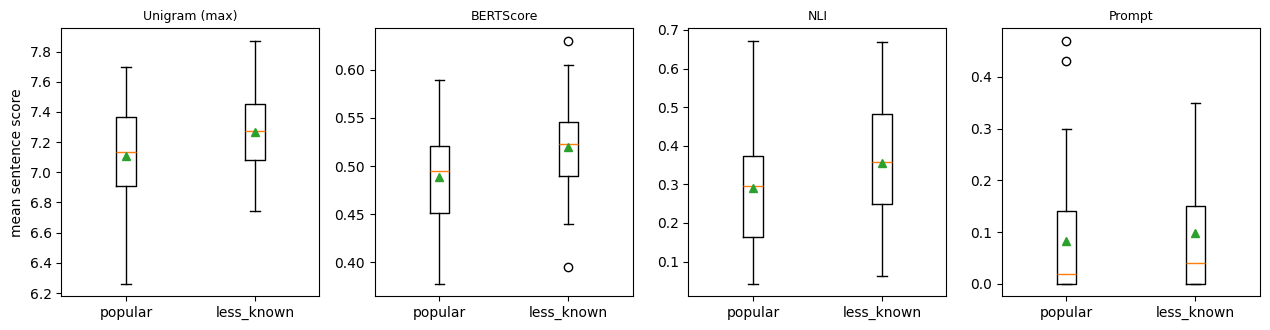

In [12]:
rng = np.random.default_rng(SEED)
def passage_means(method): return {i: float(np.mean(v)) for i, v in SC[method].items()}

rows = []
for m in METHODS:
    pm = passage_means(m)
    pop = np.array([pm[i] for i in IDS if by_id[i]["tier"] == "popular"]); lk = np.array([pm[i] for i in IDS if by_id[i]["tier"] == "less_known"])
    if len(pop) < 2 or len(lk) < 2: continue
    diffs = [rng.choice(lk, len(lk)).mean() - rng.choice(pop, len(pop)).mean() for _ in range(N_BOOT)]
    rows.append({"method": m, "popular": pop.mean(), "less_known": lk.mean(), "diff (less_known - popular)": lk.mean() - pop.mean(),
                 "95% CI": f"[{np.percentile(diffs, 2.5):+.3f}, {np.percentile(diffs, 97.5):+.3f}]", "n_popular": len(pop), "n_less_known": len(lk)})
if rows:
    display(pd.DataFrame(rows).round(3).style.hide(axis="index"))
    fig, axes = plt.subplots(1, len(METHODS), figsize=(3.2 * len(METHODS), 3.4), squeeze=False)
    for ax, m in zip(axes[0], METHODS):
        pm = passage_means(m)
        ax.boxplot([[pm[i] for i in IDS if by_id[i]["tier"] == t] for t in ("popular", "less_known")], showmeans=True); ax.set_xticklabels(["popular", "less_known"])
        ax.set_title(m, fontsize=9); ax.set_ylabel("mean sentence score" if m == METHODS[0] else "")
    plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "newdom_tier_boxplots.png"), dpi=150); plt.show()
else:
    print("need >= 2 topics in each tier for this comparison")

In [13]:
long = pd.DataFrame([{"id": i, "domain": by_id[i]["domain"], "tier": by_id[i]["tier"], "topic": by_id[i]["topic"], "sent_idx": j, "sentence": s,
                      **{m: float(SC[m][i][j]) for m in METHODS}}
                     for i in IDS for j, s in enumerate(by_id[i]["sentences"])])
if len(METHODS) > 1:
    corr = long[METHODS].corr(method="spearman")
    print("Spearman correlation between methods (sentence level):"); display(corr.round(2))
long["consensus_rank"] = long[METHODS].rank(pct=True).mean(axis=1)          # 1.0 = ranked as the most inconsistent by every method
pd.set_option("display.max_colwidth", 140)
print("\nTop 12 most suspicious sentences:")
display(long.sort_values("consensus_rank", ascending=False).head(12)[["tier", "topic", "sentence"] + METHODS].round(2))
print("Top 6 most consistent sentences:")
display(long.sort_values("consensus_rank").head(6)[["tier", "topic", "sentence"] + METHODS].round(2))

Spearman correlation between methods (sentence level):


,Unigram (max),BERTScore,NLI,Prompt
Unigram (max),1.00,0.64,0.40,0.08
BERTScore,0.64,1.00,0.48,0.13
NLI,0.40,0.48,1.00,0.47
Prompt,0.08,0.13,0.47,1.00



Top 12 most suspicious sentences:


,tier,topic,sentence,Unigram (max),BERTScore,NLI,Prompt
141,popular,the history of the Nintendo company,"The company diversified into other businesses, including taxis and love hotels, before returning to the gaming industry in the 1960s.",8.02,0.65,0.94,1.00
244,less_known,the history of the Steiff toy company,"Initially producing small, jointed elephants as gifts for her blind nephew, Steiff's innovative design and use of high-quality materials...",7.99,0.69,0.98,0.70
262,less_known,the history of the Qantas airline,"It became the first airline in the world to operate a scheduled international service in 1935, flying from Charleville to Cloncurry in Q...",8.00,0.68,0.97,0.50
272,less_known,the history of the Carlsberg brewing company,"Initially, the company produced beer using a new brewing method developed by German brewer, Wilhelm Ludwig Valentin, which involved usin...",7.95,0.72,0.99,0.60
149,popular,the history of the Nokia company,"Today, Nokia continues to operate as a telecommunications infrastructure and technology company, having sold its mobile phone business t...",8.00,0.59,0.99,0.60
201,popular,the history of the Volkswagen company,"The company has faced controversy in recent years due to emissions scandals, but remains a major player in the global automotive industry.",8.00,0.64,0.80,0.55
3,popular,the founding of the World Wide Web,"The first web page was created in 1991, and the first web browser, called WorldWideWeb, was released in 1990.",7.91,0.62,0.95,1.00
377,less_known,the Mpemba effect,"Mpemba noticed that hotter water from a nearby spring would freeze faster than the colder water from a nearby river, which led him to be...",7.82,0.74,0.96,0.90
185,popular,the history of the Samsung company,"The company's breakthrough product was the Samsung SG-100, the world's first 32-bit microprocessor, which was launched in 1991.",7.88,0.64,0.86,1.00
17,popular,the Apollo 11 moon landing,"Aldrin followed closely behind, and the two spent the next two and a half hours collecting samples and conducting experiments before rej...",7.87,0.73,0.86,0.50


Top 6 most consistent sentences:


,tier,topic,sentence,Unigram (max),BERTScore,NLI,Prompt
318,popular,nuclear fission,"Nuclear fission is a process in which the nucleus of an atom is split into smaller parts, releasing a significant amount of energy.",5.46,0.25,0.00,0.0
322,popular,the Krebs cycle,"The Krebs cycle, also known as the citric acid cycle, is a series of chemical reactions that occur in the mitochondria of eukaryotic cells.",5.48,0.12,0.01,0.0
111,less_known,the Battle of Plassey in 1757,"The Battle of Plassey, which took place on June 23, 1757, was a significant event in the history of British colonial expansion in India.",5.83,0.16,0.00,0.0
101,less_known,the Carrington Event solar storm of 1859,"The Carrington Event, which occurred in 1859, was one of the most powerful solar storms ever recorded.",5.40,0.24,0.00,0.0
19,popular,the sinking of the Titanic,"On April 14, 1912, the RMS Titanic, a luxurious ocean liner, struck an iceberg in the North Atlantic Ocean.",5.31,0.27,0.01,0.0
326,popular,CRISPR gene editing,CRISPR gene editing is a revolutionary technology that allows scientists to precisely and efficiently manipulate DNA sequences.,5.85,0.28,0.00,0.0


## Evaluation against human labels

In [14]:
def auc_pr(y, s):
    P, R, _ = precision_recall_curve(y, s); return auc(R, P)

def task_units(its, scores, task):
    per = []
    for it in its:
        hum = it["hum"]; m = np.isfinite(hum)
        if not m.any(): continue
        s = np.asarray(scores[it["id"]], float)[m]; h = hum[m]
        if task == "NonFact":   y, sc = (h > 0.499).astype(int), s
        elif task == "Factual": y, sc = (h < 0.499).astype(int), -s
        else:                                                    # NonFact*
            if h.mean() >= 0.99: continue
            y, sc = (h > 0.99).astype(int), s
        per.append((y, sc))
    return per

def _metrics(per):
    y = np.concatenate([p[0] for p in per]); s = np.concatenate([p[1] for p in per])
    if len(y) == 0 or y.sum() == 0 or y.sum() == len(y): return None
    return 100 * auc_pr(y, s), 100 * roc_auc_score(y, s), 100 * y.mean(), len(y)

def evaluate(scores, task, select=None, n_boot=N_BOOT):
    its = [it for it in items if select is None or select(it)]
    per = task_units(its, scores, task)
    base = _metrics(per) if per else None
    if base is None: return None
    out = {"AUC_PR": base[0], "AUROC": base[1], "random": base[2], "n_units": base[3], "n_topics": len(per)}
    if n_boot and len(per) > 2:
        bs = [r for r in (_metrics([per[k] for k in rng.integers(0, len(per), len(per))]) for _ in range(n_boot)) if r is not None]
        if bs:
            a = np.array(bs); out.update(AUC_PR_lo=np.percentile(a[:, 0], 2.5), AUC_PR_hi=np.percentile(a[:, 0], 97.5),
                                         AUROC_lo=np.percentile(a[:, 1], 2.5), AUROC_hi=np.percentile(a[:, 1], 97.5))
    return out

def passage_corr(scores, select=None):
    ps, hs = [], []
    for it in items:
        if select is not None and not select(it): continue
        m = np.isfinite(it["hum"])
        if m.any(): ps.append(float(np.mean(np.asarray(scores[it["id"]])[m]))); hs.append(float(it["hum"][m].mean()))
    if len(ps) < 5 or np.std(hs) == 0 or np.std(ps) == 0: return np.nan, np.nan, len(ps)
    return 100 * pearsonr(ps, hs)[0], 100 * spearmanr(ps, hs)[0], len(ps)

GROUPS = {"ALL": None}
for d in sorted({it["domain"] for it in items}): GROUPS[d] = (lambda it, d=d: it["domain"] == d)
for t in ("popular", "less_known"):               GROUPS[t] = (lambda it, t=t: it["tier"] == t)
TASKS = ["NonFact", "NonFact*", "Factual"]

def fmt(r, k="AUC_PR"):
    if r is None: return "n/a"
    lo, hi = r.get(k + "_lo"), r.get(k + "_hi")
    return f"{r[k]:.1f}" + (f" [{lo:.0f}-{hi:.0f}]" if lo is not None else "")

RES = {}
if HAVE_LABELS:
    for task in TASKS:
        for m in METHODS:
            for g, sel in GROUPS.items(): RES[(task, m, g)] = evaluate(SC[m], task, sel, n_boot=N_BOOT if g == "ALL" else 300)
    for task in TASKS:
        print(f"\n=== {task} - AUC-PR x100 [95% topic-bootstrap CI for ALL]  (random baseline = positive rate) ===")
        tab = pd.DataFrame({g: {m: fmt(RES[(task, m, g)]) for m in METHODS} for g in GROUPS})
        tab.loc["random (positive rate)"] = [f"{RES[(task, METHODS[0], g)]['random']:.1f}" if RES[(task, METHODS[0], g)] else "n/a" for g in GROUPS]
        tab.loc["n sentences"] = [str(RES[(task, METHODS[0], g)]["n_units"]) if RES[(task, METHODS[0], g)] else "n/a" for g in GROUPS]
        display(tab)
    print("\n=== AUROC x100 on NonFact ===")
    display(pd.DataFrame({g: {m: fmt(RES[("NonFact", m, g)], "AUROC") for m in METHODS} for g in GROUPS}))
    print("\n=== Passage level: Pearson / Spearman (x100) ===")
    pc = {m: passage_corr(SC[m]) for m in METHODS}
    display(pd.DataFrame({m: {"Pearson": f"{v[0]:.1f}", "Spearman": f"{v[1]:.1f}", "n topics": v[2]} for m, v in pc.items()}).T)
else:
    print("No labels yet - skipped. Fill in the annotation template from notebook 01, save it as new_domain_annotation.csv and re-run from section 3.")


=== NonFact - AUC-PR x100 [95% topic-bootstrap CI for ALL]  (random baseline = positive rate) ===


,ALL,company_history,historical_event,scientific_concept,popular,less_known
Unigram (max),4.5 [2-8],n/a,8.8 [3-17],7.8 [3-16],5.1 [1-9],3.9 [1-9]
BERTScore,6.6 [2-13],n/a,9.3 [3-19],12.9 [2-31],6.6 [2-16],7.6 [1-22]
NLI,9.6 [2-22],n/a,17.7 [2-40],55.3 [3-75],7.2 [2-27],14.0 [1-32]
Prompt,11.3 [2-24],n/a,16.7 [3-39],41.6 [1-62],11.8 [2-29],11.0 [0-39]
random (positive rate),4.6,n/a,8.2,5.9,5.3,4.0
n sentences,411,n/a,134,136,209,202



=== NonFact* - AUC-PR x100 [95% topic-bootstrap CI for ALL]  (random baseline = positive rate) ===


,ALL,company_history,historical_event,scientific_concept,popular,less_known
Unigram (max),1.4 [0-3],n/a,0.5 [0-2],5.6 [2-12],0.4 [0-1],2.6 [1-7]
BERTScore,6.5 [0-18],n/a,0.8 [1-3],17.2 [8-56],0.6 [1-2],10.0 [4-51]
NLI,9.1 [0-27],n/a,0.4 [0-1],85.2 [63-100],0.2 [0-1],16.1 [6-36]
Prompt,5.6 [0-16],n/a,0.4 [0-1],56.5 [52-62],0.2 [0-1],13.3 [5-43]
random (positive rate),1.2,n/a,0.7,2.9,0.5,2.0
n sentences,411,n/a,134,136,209,202



=== Factual - AUC-PR x100 [95% topic-bootstrap CI for ALL]  (random baseline = positive rate) ===


,ALL,company_history,historical_event,scientific_concept,popular,less_known
Unigram (max),96.3 [93-99],n/a,93.0 [86-99],97.4 [93-100],95.5 [92-99],97.4 [94-100]
BERTScore,97.2 [95-99],n/a,94.7 [90-99],97.0 [92-100],96.9 [94-100],97.6 [93-100]
NLI,96.8 [94-99],n/a,92.3 [84-98],98.9 [97-100],95.2 [90-99],98.7 [97-100]
Prompt,97.6 [96-99],n/a,95.5 [91-98],98.4 [95-100],97.0 [95-99],98.3 [96-100]
random (positive rate),95.4,n/a,91.8,94.1,94.7,96.0
n sentences,411,n/a,134,136,209,202



=== AUROC x100 on NonFact ===


,ALL,company_history,historical_event,scientific_concept,popular,less_known
Unigram (max),53.3 [45-62],n/a,55.0 [43-73],66.3 [57-81],52.5 [41-67],53.4 [46-69]
BERTScore,61.6 [50-74],n/a,58.8 [42-78],67.1 [57-90],61.6 [43-80],62.9 [53-89]
NLI,63.5 [46-79],n/a,54.4 [40-73],85.9 [76-99],55.0 [42-76],77.7 [58-95]
Prompt,60.1 [46-75],n/a,56.1 [46-68],76.3 [44-96],55.5 [44-67],67.6 [32-87]



=== Passage level: Pearson / Spearman (x100) ===


,Pearson,Spearman,n topics
Unigram (max),20.7,20.5,90
BERTScore,27.4,21.3,90
NLI,16.7,9.5,90
Prompt,20.5,24.6,90


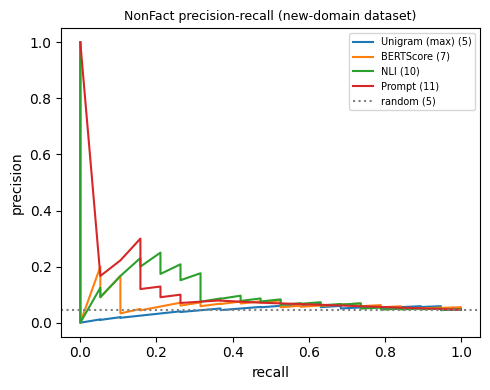

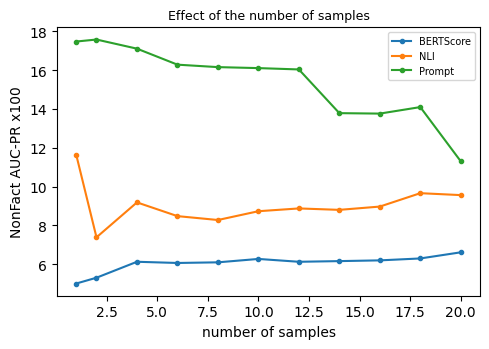

In [15]:
if HAVE_LABELS:
    # PR curves on NonFact (all labelled sentences)
    per_all = {m: task_units(items, SC[m], "NonFact") for m in METHODS}
    fig, ax = plt.subplots(figsize=(5, 4))
    for m in METHODS:
        y = np.concatenate([p[0] for p in per_all[m]]); s = np.concatenate([p[1] for p in per_all[m]])
        if y.sum() and y.sum() < len(y): P, R, _ = precision_recall_curve(y, s); ax.plot(R, P, label=f"{m} ({100 * auc(R, P):.0f})")
    ax.axhline(y.mean(), color="grey", ls=":", label=f"random ({100 * y.mean():.0f})")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("NonFact precision-recall (new-domain dataset)", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "newdom_pr_curves.png"), dpi=150); plt.show()

    # effect of the number of samples (matrix methods only): first n of the cached samples
    n_max = min(len(it["samples"]) for it in items)
    Ns = [n for n in (1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20) if n <= n_max]
    fig, ax = plt.subplots(figsize=(5, 3.6))
    for m in [k for k in METHODS if k in MT]:
        vals = []
        for n in Ns:
            sc = {i: ((1.0 - M[:, :n].mean(axis=1)) if m == "BERTScore" else M[:, :n].mean(axis=1)) for i, M in MT[m].items()}
            r = evaluate(sc, "NonFact", None, n_boot=0); vals.append(r["AUC_PR"] if r else np.nan)
        ax.plot(Ns, vals, marker="o", ms=3, label=m)
    ax.set_xlabel("number of samples"); ax.set_ylabel("NonFact AUC-PR x100"); ax.set_title("Effect of the number of samples", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "newdom_num_samples.png"), dpi=150); plt.show()

## Export

In [16]:
out = long.drop(columns=["consensus_rank"]).copy()
out["human_label"] = [by_id[i]["hum"][j] for i, j in zip(out["id"], out["sent_idx"])]
out["consensus_rank"] = long["consensus_rank"].values
out.to_csv(os.path.join(DATA_DIR, "new_domain_scores.csv"), index=False, encoding="utf-8-sig")

summary = {"dataset_hash": DS_HASH, "n_topics": len(items), "n_sentences": len(out), "methods": METHODS, "have_labels": HAVE_LABELS,
           "n_labelled_sentences": int(out["human_label"].notna().sum()), "prompt_llm": PROMPT_LLM if "Prompt" in METHODS else None}
if rows: summary["tier_comparison"] = rows
if HAVE_LABELS:
    summary["results"] = {f"{t}|{m}|{g}": {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in r.items()}
                          for (t, m, g), r in RES.items() if r is not None}
json.dump(summary, open(os.path.join(DATA_DIR, "new_domain_summary.json"), "w"), indent=2, default=float)
print("wrote new_domain_scores.csv and new_domain_summary.json to", DATA_DIR)
display(out.head(5)[["id", "tier", "sent_idx", "sentence"] + METHODS])

wrote new_domain_scores.csv and new_domain_summary.json to /content/drive/MyDrive/NewDatasetConstruction/new_domain


,id,tier,sent_idx,sentence,Unigram (max),BERTScore,NLI,Prompt
0,hist_000,popular,0,"The World Wide Web, the system of interconnected hypertext documents accessed via the Internet, was founded by British computer scientis...",5.716662,0.239457,0.038231,0.0
1,hist_000,popular,1,"Berners-Lee proposed a project to create a system for sharing information among researchers, which would allow them to navigate between ...",7.913887,0.490498,0.052966,0.0
2,hist_000,popular,2,"He developed the first web browser and editor, as well as the first web server, and published a proposal for the web's architecture in 1...",7.220740,0.624714,0.627003,0.0
3,hist_000,popular,3,"The first web page was created in 1991, and the first web browser, called WorldWideWeb, was released in 1990.",7.913887,0.622191,0.950349,1.0
4,hist_000,popular,4,The web quickly gained popularity and transformed the way people access and share information.,7.913887,0.559733,0.058893,0.0
